In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/playground-series-s6e11/sample_submission.csv
/kaggle/input/competitions/playground-series-s6e11/train.csv
/kaggle/input/competitions/playground-series-s6e11/test.csv


In [2]:
import pandas as pd


DATA_DIR = "/kaggle/input/competitions/playground-series-s6e11"
ID, TARGET = "id", "is_fraud"

train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
sub = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")

features = [c for c in train.columns if c not in (ID, TARGET)]

# 1. Kích thước và cột: train và test phải có cùng các cột đầu vào
print("=== 1. KÍCH THƯỚC VÀ CỘT ===")
print("train:", train.shape, "| test:", test.shape, "| sample_submission:", sub.shape)
print("Cột đầu vào có ở train nhưng thiếu ở test:", sorted(set(features) - set(test.columns)))
print("Cột có ở test nhưng không có ở train:", sorted(set(test.columns) - set(train.columns)))

# 2. Kiểu dữ liệu, số giá trị khác nhau, giá trị thiếu
print("\n=== 2. KIỂU DỮ LIỆU VÀ GIÁ TRỊ THIẾU ===")
print(pd.DataFrame({
    "kiểu": train.dtypes,
    "số giá trị khác nhau": train.nunique(),
    "thiếu (train)": train.isna().sum(),
    "thiếu (test)": test.isna().sum(),
}))

# 3. Nhãn: tỷ lệ fraud, nhãn thiếu hoặc ngoài 0/1
print("\n=== 3. NHÃN ===")
print(train[TARGET].value_counts(dropna=False))
print("Tỷ lệ fraud (%):", round(train[TARGET].mean() * 100, 3))
print("Nhãn thiếu:", train[TARGET].isna().sum(),
      "| nhãn ngoài 0/1:", (train[TARGET].notna() & ~train[TARGET].isin([0, 1])).sum())

# 4. ID: thiếu, trùng
print("\n=== 4. ID ===")
print("ID thiếu (train / test):", train[ID].isna().sum(), "/", test[ID].isna().sum())
print("ID trùng (train / test):", train[ID].duplicated().sum(), "/", test[ID].duplicated().sum())
print("ID có ở cả train và test:", len(set(train[ID]) & set(test[ID])))

# 5. Trùng lặp: các dòng giống nhau ở mọi đặc trưng 
print("\n=== 5. DÒNG TRÙNG ĐẶC TRƯNG ===")
print("Bản sao thừa (train / test):",
      train.duplicated(subset=features).sum(), "/", test.duplicated(subset=features).sum())

dup = train[train.duplicated(subset=features, keep=False)]
if len(dup) == 0:
    conflict = 0
else:
    conflict = int((dup.groupby(features, dropna=False)[TARGET].nunique() > 1).sum())
print("Nhóm trùng đặc trưng nhưng khác nhãn:", conflict)

# 6. Dòng train có đặc trưng giống hệt một dòng test
print("\n=== 6. TRAIN GIỐNG TEST ===")
test_keys = test[features].drop_duplicates()
n_match = len(train[features].merge(test_keys, on=features, how="inner"))
print("Dòng train giống hệt một dòng test:", n_match)



=== 1. KÍCH THƯỚC VÀ CỘT ===
train: (699960, 26) | test: (299984, 25) | sample_submission: (299984, 2)
Cột đầu vào có ở train nhưng thiếu ở test: []
Cột có ở test nhưng không có ở train: []

=== 2. KIỂU DỮ LIỆU VÀ GIÁ TRỊ THIẾU ===
                                 kiểu  số giá trị khác nhau  thiếu (train)  \
account_balance_usd           float64                 43317              0   
amount_usd                    float64                 13387              0   
auth_method                    object                     5              0   
billing_shipping_mismatch        bool                     2              0   
card_age_months                 int64                    49              0   
card_type                      object                     5              0   
channel                        object                     5              0   
customer_age                    int64                    64              0   
cvv_retry_count                 int64                     4       

=== 1. CỘT SỐ ===

--- train ---
                         min      1%      50%      mean      99%       max       std    skew  % bằng 0
amount_usd              1.00    4.42    27.25    79.893   936.95   6872.69   205.174   7.002     0.000
hours_since_last_txn    0.01    0.11     4.73     6.634    29.38     51.98     6.290   1.823     0.000
txn_count_last_24h      0.00    0.00     3.00     2.984     7.00     11.00     1.499   0.436     2.638
distance_from_home_km   0.00    0.08    10.22    13.588    47.86     57.93    11.617   1.060     0.002
card_age_months        25.00   34.00    47.00    46.863    60.00     73.00     5.579   0.133     0.000
customer_age           18.00   19.00    52.00    51.430    81.00     81.00    17.899  -0.141     0.000
account_balance_usd    58.25  454.85  1382.74  2064.998  9082.81  99701.39  3400.133  14.436     0.000
cvv_retry_count         0.00    0.00     0.00     0.085     1.00      3.00     0.290   3.319    91.732
velocity_score          0.00    0.00    

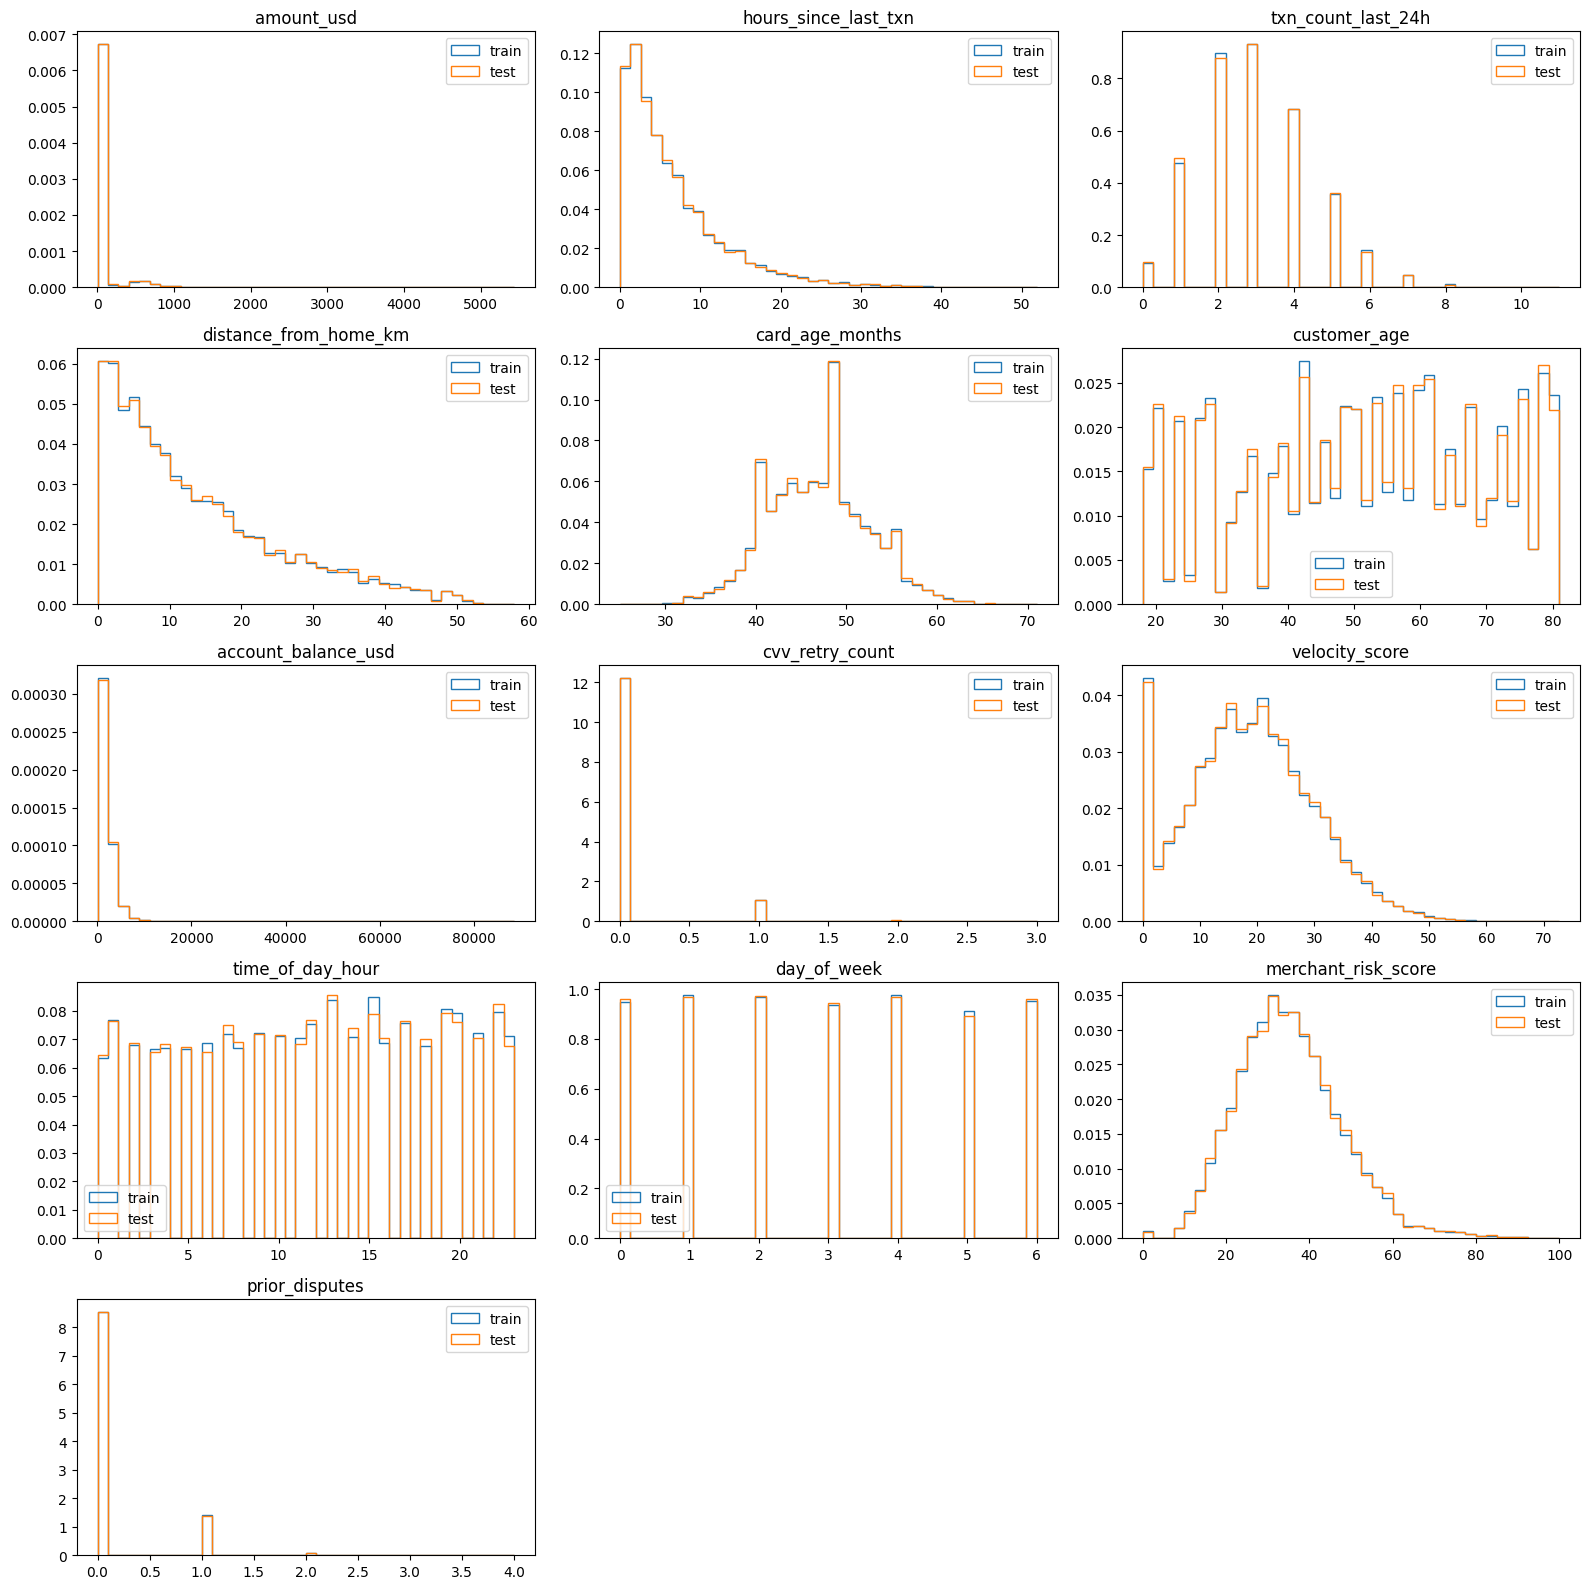

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Task 2: phân bố các đặc trưng. 

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

DATA_DIR = "/kaggle/input/competitions/playground-series-s6e11"

train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")

numeric_cols = [
    "amount_usd", "hours_since_last_txn", "txn_count_last_24h",
    "distance_from_home_km", "card_age_months", "customer_age",
    "account_balance_usd", "cvv_retry_count", "velocity_score",
    "time_of_day_hour", "day_of_week", "merchant_risk_score", "prior_disputes",
]
categorical_cols = ["merchant_category", "card_type", "auth_method", "channel", "device_type"]
boolean_cols = [
    "is_foreign_transaction", "is_new_merchant", "used_vpn",
    "ip_country_mismatch", "billing_shipping_mismatch", "is_ai_generated_scam_attempt",
]

# 1. Cột số: khoảng giá trị, độ lệch, tỷ lệ bằng 0
print("=== 1. CỘT SỐ ===")
for name, df in [("train", train), ("test", test)]:
    s = df[numeric_cols]
    table = s.describe(percentiles=[0.01, 0.5, 0.99]).T[["min", "1%", "50%", "mean", "99%", "max", "std"]]
    table["skew"] = s.skew()
    table["% bằng 0"] = (s == 0).mean() * 100
    print(f"\n--- {name} ---")
    print(table.round(3))

# 2. Cột chữ: tỷ lệ (%) từng giá trị ở train và test
print("\n=== 2. CỘT CHỮ ===")
for col in categorical_cols:
    table = pd.concat(
        [train[col].value_counts(normalize=True).mul(100).rename("train %"),
         test[col].value_counts(normalize=True).mul(100).rename("test %")],
        axis=1,
    ).fillna(0)
    print(f"\n--- {col} ---")
    print(table.sort_values("train %", ascending=False).round(3))

# 3. Cột bool: tỷ lệ True (%) ở train và test
print("\n=== 3. CỘT BOOL ===")
print(pd.DataFrame({
    "train %": train[boolean_cols].mean() * 100,
    "test %": test[boolean_cols].mean() * 100,
}).round(3))

# 4. Các cặp cột số tương quan mạnh với nhau (|corr| > 0.5), chưa dùng nhãn
print("\n=== 4. CẶP CỘT SỐ TƯƠNG QUAN MẠNH ===")
corr = train[numeric_cols].corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
strong = pairs[pairs > 0.5].sort_values(ascending=False)
print(strong.round(3) if len(strong) else "Không có cặp nào vượt 0.5.")

# 5. Histogram train và test chồng lên nhau (vẽ tối đa 50.000 giá trị mỗi tập)
print("\n=== 5. HISTOGRAM TRAIN / TEST ===")
ncols = 3
nrows = -(-len(numeric_cols) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.2 * nrows))
axes = axes.ravel()

for ax, col in zip(axes, numeric_cols):
    tr = train[col].sample(n=min(50000, len(train)), random_state=42)
    te = test[col].sample(n=min(50000, len(test)), random_state=42)
    bins = np.histogram_bin_edges(np.concatenate([tr, te]), bins=40)
    ax.hist(tr, bins=bins, density=True, histtype="step", label="train")
    ax.hist(te, bins=bins, density=True, histtype="step", label="test")
    ax.set_title(col)
    ax.legend()

for ax in axes[len(numeric_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()